# CNN experiment summary and model choice

Documents what the CNN experiments (Thiago Leão) found and which model goes into the paper. It runs from the shipped files only
(`data/folds.csv` and `cnn/results/*.csv`), without GPU or tensors.

**Read this first.** Every number below was computed on the original CNN split, a CRC32 hash of the block id, **not** on `data/folds.csv`.
They are good for comparing CNN variants with each other. They are **not comparable** with the classical models and must not enter the
paper tables until the final model is re-run on the shared folds (`cnn_setup.fold_of`).

In [1]:
import sys, pathlib, zlib
for _p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent, pathlib.Path.cwd() / "cnn"):
    if (_p / "cnn_setup.py").exists():
        sys.path.insert(0, str(_p)); break
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cnn_setup as cs

RESULTS = pathlib.Path(cs.__file__).parent / "results"
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2a6f97", "#9aa5b1"

## 1. The two fold definitions

The CNN notebooks hashed the block id (`city_bx_by`) with CRC32 and took it modulo 5; the classical models use `StratifiedGroupKFold`
on the same 2,560 m blocks. Both are spatial block splits, so neither leaks within itself, but they assign blocks to different folds.

In [2]:
f = pd.read_csv(cs.FOLDS_CSV)
f["fold_crc32"] = [zlib.crc32(b.encode()) % 5 for b in f["block"]]
print(f"agreement between the two assignments: {(f.fold == f.fold_crc32).mean():.1%} (chance level is 20%)\n")

rows = []
for name, col in (("CNN experiments (CRC32)", "fold_crc32"), ("shared folds.csv", "fold")):
    rows.append({"split": name, "train (folds 2-4)": int((~f[col].isin([0, 1])).sum()),
                 "inner validation (fold 1)": int((f[col] == 1).sum()), "hold-out (fold 0)": int((f[col] == 0).sum())})
print(pd.DataFrame(rows).to_string(index=False))
print("\nrows by (shared fold, CRC32 fold):")
print(pd.crosstab(f["fold"], f["fold_crc32"]))

agreement between the two assignments: 18.2% (chance level is 20%)

                  split  train (folds 2-4)  inner validation (fold 1)  hold-out (fold 0)
CNN experiments (CRC32)               9093                       4694               3167
       shared folds.csv              10339                       3440               3175

rows by (shared fold, CRC32 fold):
fold_crc32    0     1    2    3    4
fold                                
0           764   584  633  737  457
1           455  1220  647  266  852
2           574   872  532  444  460
3           780   479  871  304  975
4           594  1539  739  910  266


The CRC32 partition reproduces exactly the sizes in Thiago's logs (9,093 / 4,694 / 3,167). With the shared folds the CNN hold-out would
contain points that the classical models trained on, so results cannot be compared or stacked by `sample_id`. Decision: the final CNN is
re-run on `data/folds.csv`.

## 2. U-Net architecture search (run `ac6d3912`)

Three rounds on the validation fold: round 1 varies width, depth and convolutions; round 2 adds squeeze-and-excitation (`se`) and
per-season temporal attention (`tatt`); round 3 tries a mixed loss on the best network. Metrics are per pixel in metres;
`macro` is the mean of the RMSE over the height classes 2, 6, 15, 30 m.

                 key  n_params  val_macro_RMSE_px  val_RMSE_px  val_RMSE_bldg_px  val_MAE_px  val_R2_px  val_bias_px
0      r3_u48_c2+mix    753073              9.662       10.168            11.848       5.785      0.637       -1.044
1          r1_u48_c2    753073              9.971       10.461            12.358       5.716      0.615       -1.695
2       r2_u48_c2+se    768589              9.986       10.994            13.135       5.900      0.575       -3.164
3       r1_u32_d3_c2   1375521             10.070       10.974            13.080       5.931      0.577       -2.922
4          r1_u64_c2   1326657             10.095       10.315            12.150       5.621      0.626       -1.333
5          r1_u32_c3    433697             10.118       10.637            12.618       5.809      0.602       -2.058
6          r1_u32_c2    340769             10.281       11.457            13.730       6.114      0.539       -3.559
7  r2_u48_c2+se+tatt    792350             10.502       11.902  

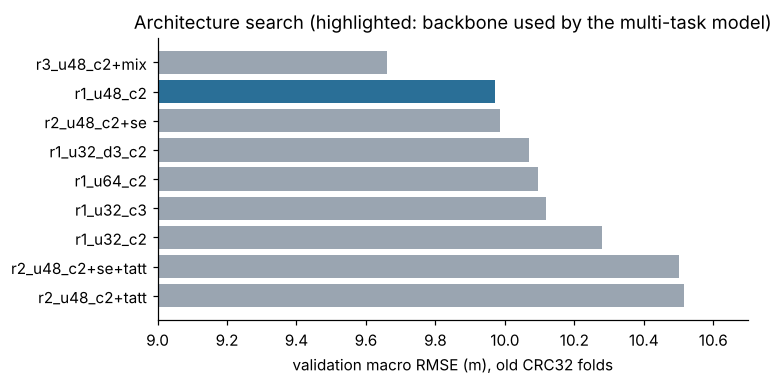

In [3]:
arch = pd.read_csv(RESULTS / "arch_search_results.csv")
cols = ["key", "n_params", "val_macro_RMSE_px", "val_RMSE_px", "val_RMSE_bldg_px", "val_MAE_px", "val_R2_px", "val_bias_px"]
arch = arch.sort_values("val_macro_RMSE_px")[cols].reset_index(drop=True)
print(arch.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.6))
colors = [BLUE if k == "r1_u48_c2" else GREY for k in arch["key"]]
ax.barh(arch["key"][::-1], arch["val_macro_RMSE_px"][::-1], color=colors[::-1])
ax.set_xlim(9, 10.7); ax.set_xlabel("validation macro RMSE (m), old CRC32 folds")
ax.set_title("Architecture search (highlighted: backbone used by the multi-task model)")
plt.tight_layout(); plt.show()

Findings, all on the old validation fold:

* Attention did not help: `se` and `tatt` variants are 0.01 to 0.54 m worse in macro RMSE than the plain `u48_c2`, and `se+tatt` is among the worst.
* `u48_c2` (filters 48/96/192, two convolutions per block, 753k parameters) beats both smaller and larger plain networks.
* The mixed loss (`r3_u48_c2+mix`) has the lowest macro RMSE (9.66 m) and the least bias, but the search script had already fixed
  `r1_u48_c2` as best, so the saved `best_spec` and the multi-task model use the RMSE-loss `u48_c2`. Not a leak; just a selection that
  was not updated after round 3.

## 3. Input context size

     key  input px  eval_crop  val_macro_RMSE_px  val_RMSE_px  val_RMSE_bldg_px  val_R2_px
ctx_px11        11         11              9.607       10.218            12.004      0.633
ctx_px21        21         11              9.007        9.678            11.366      0.671
ctx_px33        33         11              8.878        9.411            10.996      0.689


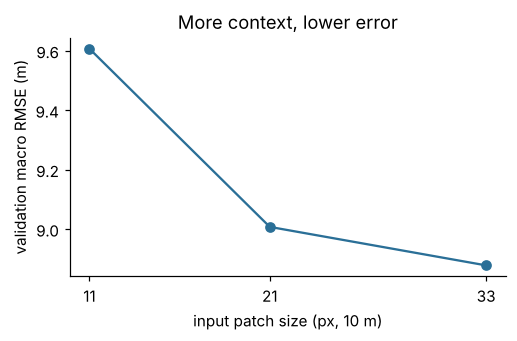

In [4]:
ctx = pd.read_csv(RESULTS / "context_results.csv")
ctx["input px"] = ctx["px"]
print(ctx[["key", "input px", "eval_crop", "val_macro_RMSE_px", "val_RMSE_px", "val_RMSE_bldg_px", "val_R2_px"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.plot(ctx["px"], ctx["val_macro_RMSE_px"], marker="o", color=BLUE)
ax.set_xticks(ctx["px"]); ax.set_xlabel("input patch size (px, 10 m)"); ax.set_ylabel("validation macro RMSE (m)")
ax.set_title("More context, lower error"); plt.tight_layout(); plt.show()

The same `u48_c2` network trained on 11, 21 and 33 px inputs and scored on the central 11 px: macro RMSE falls from 9.61 to 9.01 to 8.88 m.
Larger context helps. The multi-task model still uses 33 px inputs (`PX = 33`).

## 4. Synthetic data for tall buildings

Variants of the training set on the same validation fold (`smote_hybrid_comparison.csv`; column names are in Portuguese in the source file).

           training set  n train  RMSE   MAE   bias    R2  RMSE_h_12_30  RMSE_h_30p
  train_rot4x_plus_cgan    53096 8.950 6.084  0.287 0.568         7.508      12.532
        train_plus_cgan    25817 9.338 6.291  0.007 0.529         7.685      13.417
train_plus_guided_mixup    25817 9.367 6.273 -1.644 0.526         6.818      14.177
  train_plus_all_smotes    59265 9.389 6.376 -1.090 0.524         7.302      13.803
  train_plus_smoter_knn    25817 9.617 6.489 -0.585 0.501         8.107      13.682


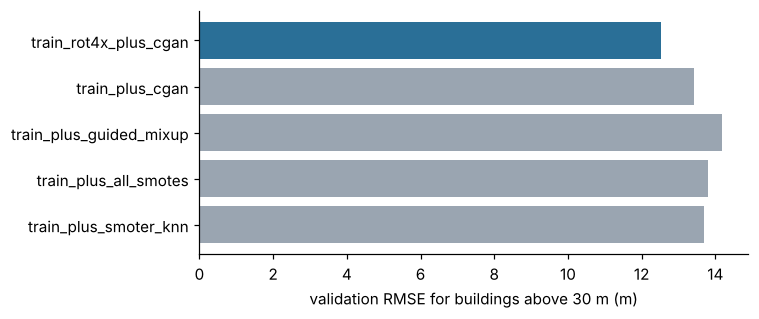

In [5]:
sm = pd.read_csv(RESULTS / "smote_hybrid_comparison.csv")
sm = sm.rename(columns={"Configuração": "training set", "N_Treino": "n train"})
print(sm[["training set", "n train", "RMSE", "MAE", "bias", "R2", "RMSE_h_12_30", "RMSE_h_30p"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(sm["training set"][::-1], sm["RMSE_h_30p"][::-1], color=[BLUE if s == "train_rot4x_plus_cgan" else GREY for s in sm["training set"][::-1]])
ax.set_xlabel("validation RMSE for buildings above 30 m (m)"); plt.tight_layout(); plt.show()

Rotations plus cGAN patches (`train_rot4x_plus_cgan`) is the best set overall (RMSE 8.95 m, R2 0.57) and for buildings above 30 m
(12.5 m against 13.4 to 14.2 m for the others). **Missing control:** the file has no "rotations only, no synthetic patches" row, so the
gain from the cGAN is not separated from the gain from rotation augmentation (front 3 in `possiveis_melhorias.md`). The cGAN was fitted
on the old training rows; on the shared folds it has to be regenerated from the new training rows only.

## 5. Multi-task U-Net (final model)

Footprint head (binary cross-entropy plus Dice) and a height head over 32 log-spaced bins in metres trained where height > 0;
prediction = p(building) x conditional height, with a mask threshold chosen on validation (0.35). The numbers below are transcribed from the
output of `cnn_04_multitask_height` and of the baseline in `cnn_02_architecture_search`, both on the old folds.

In [6]:
cmp = pd.DataFrame(
    {("validation", "u48_c2"):    [9.971, 10.461, 12.358, 5.716, 0.615, -1.695],
     ("validation", "multi-task"): [10.388, 9.646, 11.460, 5.187, 0.555, -1.801],
     ("hold-out",   "u48_c2"):    [9.011, 8.746, 10.355, 4.775, 0.644, -0.772],
     ("hold-out",   "multi-task"): [9.413, 8.140, 9.698, 4.399, 0.570, -1.264]},
    index=["macro RMSE", "RMSE (all px)", "RMSE (building px)", "MAE (all px)", "R2 (all px)", "bias"])
print(cmp.to_string())

                   validation            hold-out           
                       u48_c2 multi-task   u48_c2 multi-task
macro RMSE              9.971     10.388    9.011      9.413
RMSE (all px)          10.461      9.646    8.746      8.140
RMSE (building px)     12.358     11.460   10.355      9.698
MAE (all px)            5.716      5.187    4.775      4.399
R2 (all px)             0.615      0.555    0.644      0.570
bias                   -1.695     -1.801   -0.772     -1.264


The multi-task model is better in pixel RMSE, building-pixel RMSE and MAE, on both folds (hold-out RMSE 8.14 against 8.75 m), but worse in
macro RMSE and R2. Honest reading: it improves the typical pixel and the building pixels, not the tall-building tail that macro RMSE weights.
The paper should report both metrics and say so.

## 6. Decision record

| Item | Decision |
|---|---|
| Final CNN | multi-task U-Net, backbone `u48_c2` (no attention), 33 px input, chosen by Thiago Leão |
| Folds | `data/folds.csv` via `cnn_setup.fold_of` (fold 0 hold-out, fold 1 inner validation) |
| Status of the numbers above | old CRC32 split; indicative only |
| To do before the paper | re-run the final model on shared folds; regenerate synthetic patches if used; add a no-synthetic control; save `cnn_test.csv` (and spatial out-of-fold predictions keyed by `sample_id`) so the CNN can enter the comparison and the stack |